# What FBISE's published exam results show, 2013–2020

A descriptive analysis of **public, aggregate** results of the Federal Board of
Intermediate and Secondary Education (FBISE), Islamabad, for the final-year
**SSC-II (Matric)** and **HSSC-II (Intermediate)** annual examinations.

**Privacy.** Only board-wide aggregate tables are used: counts of candidates who
enrolled, appeared and passed, by candidate type, subject group and gender. No
student names, roll numbers or individual marks were collected or stored.

**Scope.** One board (FBISE), so nothing here describes Pakistan as a whole.
Every number comes from an official FBISE PDF listed in `data/SOURCES.md`.
The research questions were fixed before any result was plotted
(`DECISIONS.md`, ADR-002).

## Setup

The notebook uses the project's tested modules in `src/` instead of
re-implementing the cleaning here. It finds the project folder whether it runs
from `notebooks/`, from the repository root, or on Kaggle (where the repository
is attached as a dataset; see `docs/KAGGLE_PUBLISHING.md`).

In [1]:
import sys
from pathlib import Path

import pandas as pd


def find_project_root() -> Path:
    kaggle = [p.parent.parent for p in Path("/kaggle/input").glob("**/src/analysis.py")]
    for folder in [Path.cwd(), *Path.cwd().parents, *kaggle]:
        if (folder / "src" / "analysis.py").exists():
            return folder
    raise FileNotFoundError("Could not find the project folder containing src/analysis.py")


ROOT = find_project_root()
sys.path.insert(0, str(ROOT))  # lets `import src` work from notebooks/ or on Kaggle

from src import analysis, plots  # noqa: E402  (must come after the sys.path line)

%matplotlib inline
plots.apply_style()
pd.set_option("display.precision", 2)
df = analysis.load_tidy(ROOT / "data" / "processed" / "results_tidy.csv")
print(f"{len(df)} rows loaded from data/processed/results_tidy.csv")

290 rows loaded from data/processed/results_tidy.csv


## Data and definitions

* **One row = one table cell**: level × year × candidate type × subject group ×
  gender. Totals printed in the gazette are kept as rows labelled `All`, so
  always filter on all three labels before adding numbers up.
* **Pass rate = passed ÷ appeared × 100**, FBISE's own definition. *Appeared* =
  enrolled − absent. Candidates whose result was declared later stay in the
  denominator, as in the gazette.
* Differences are in **percentage points (pp)**: 60% → 65% is +5 pp.
* **Regular** candidates sit the exam through an affiliated school or college;
  **private** candidates register on their own (often repeaters).
* **2020 was not an examination.** The HSSC-II 2020 gazette states that the
  exam "was not conducted due to COVID-19" and results were prepared under the
  Federal Government's promotion policy. 2020 is never pooled with exam years.
* 2013–2014 come from FBISE's *Result Statistics 2013–2017* summary, which gives
  only an overall pass percentage, so those rows have no counts.

### Coverage
Which cells exist (✓), before looking at any outcome:

In [2]:
coverage = (df.assign(has_breakdown=df["pass_rate_method"].eq("computed_from_counts"))
              .groupby(["level", "year"])
              .agg(rows=("pass_rate", "size"), breakdown=("has_breakdown", "any"),
                   assessment=("assessment", "first")))
coverage["breakdown"] = coverage["breakdown"].map({True: "✓ by type, group, gender",
                                                   False: "overall % only"})
coverage

rows                 breakdown                assessment
level year                                                          
HSSC  2013     1            overall % only               examination
      2014     1            overall % only               examination
      2015    39  ✓ by type, group, gender               examination
      2016    39  ✓ by type, group, gender               examination
      2017    39  ✓ by type, group, gender               examination
      2018    39  ✓ by type, group, gender               examination
      2020    38  ✓ by type, group, gender  no_exam_promotion_policy
SSC   2013     1            overall % only               examination
      2014     1            overall % only               examination
      2015    15  ✓ by type, group, gender               examination
      2016    15  ✓ by type, group, gender               examination
      2017    15  ✓ by type, group, gender               examination
      2018    17  ✓ by type, group, gender               examination
      2019    15  ✓ by type, group, gender               examination
      2020    15  ✓ by type, group, gender  no_exam_promotion_policy

HSSC-II **2019 is missing**: no 2019 annual gazette could be found on
fbise.edu.pk. It is left as a gap, not estimated.

---
## Q1. How did the overall pass rate change, 2013–2019?

**Method.** Plot the overall (all-candidate) pass rate per year, and beside it
the regular-candidate rate for 2015 onward, because the overall rate also moves
when the mix of regular and private candidates changes.

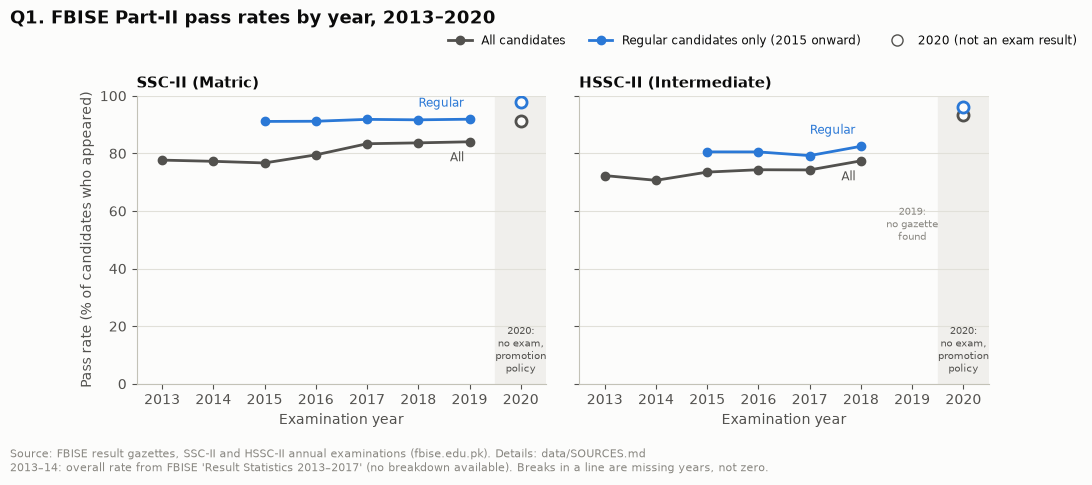

In [3]:
trend = analysis.overall_trend(df)
plots.plot_overall_trend(trend);

In [4]:
print("Change in pass rate, percentage points:")
for level, start, end in [("SSC", 2013, 2019), ("SSC", 2015, 2019),
                          ("HSSC", 2013, 2018), ("HSSC", 2015, 2018)]:
    for population in ["All candidates", "Regular candidates"]:
        if population.startswith("Regular") and start < 2015:
            continue
        change = analysis.change_between(trend, level, population, start, end)
        print(f"  {level:4} {population:19} {start}->{end}: {change:+.2f} pp")

Change in pass rate, percentage points:
  SSC  All candidates      2013->2019: +6.36 pp
  SSC  All candidates      2015->2019: +7.34 pp
  SSC  Regular candidates  2015->2019: +0.77 pp
  HSSC All candidates      2013->2018: +5.11 pp
  HSSC All candidates      2015->2018: +3.90 pp
  HSSC Regular candidates  2015->2018: +1.94 pp


In [5]:
analysis.candidate_mix(df)

candidate_type,level,year,appeared_private,appeared_regular,private_share_pct
0,HSSC,2015,13297,43099,23.58
1,HSSC,2016,12785,45247,22.03
2,HSSC,2017,11305,45874,19.77
3,HSSC,2018,11731,47837,19.69
4,HSSC,2020,11970,59512,16.75
5,SSC,2015,21149,57766,26.8
6,SSC,2016,19183,63711,23.14
7,SSC,2017,16310,68830,19.16
8,SSC,2018,15628,73815,17.47
9,SSC,2019,15137,71977,17.38


**Interpretation.** The SSC-II overall pass rate rose by about 6–7 pp over
2013/2015–2019. The regular-candidate rate barely moved (+0.8 pp, staying near
91–92%). Over the same years private candidates fell from about 27% to 17% of
those who appeared, and the private pass rate rose (see Q4 chart). So most of
the rise in the overall SSC figure sits in the private-candidate part of the
table, not in the regular-candidate rate. HSSC-II rose by about 5 pp from 2013 to
2018, and the regular rate moved little and not steadily (it dipped in 2017).

**Limitation.** This describes reported pass rates only. A higher pass rate
does not by itself show better learning: papers, marking and grading rules can
change from year to year, and the gazettes do not document such changes.

---
## Q2. Do female and male pass rates differ within the same group?

**Method.** For regular candidates, compute female − male pass rate (pp)
within each subject group and year. Comparing within groups matters because
women and men are spread very differently across groups (e.g. far more women
than men take Humanities). Cells with fewer than 100 candidates of either
gender are left out of the chart (rule fixed in ADR-002).

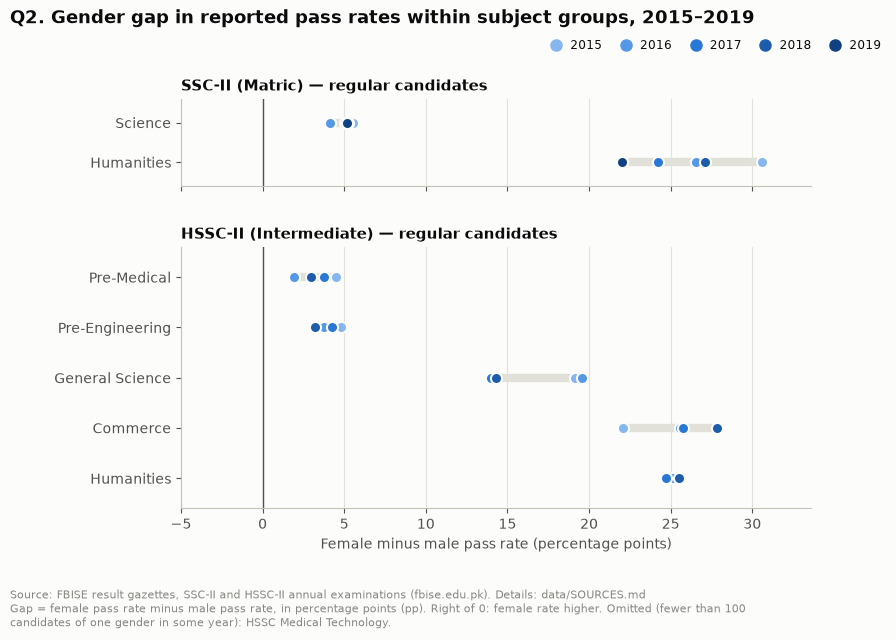

In [6]:
gaps = analysis.gender_gaps(df)
plots.plot_gender_gaps(gaps);

In [7]:
(gaps[gaps["comparable"]]
 .groupby(["level", "group"])["gap_pp"]
 .agg(["min", "max", "count"])
 .rename(columns={"min": "smallest gap (pp)", "max": "largest gap (pp)",
                  "count": "years"}))

smallest gap (pp)  largest gap (pp)  years
level group                                                      
HSSC  Commerce                     22.07             27.81      4
      General Science              13.97             19.59      4
      Humanities                   24.73             25.53      4
      Pre-Engineering               3.21              4.77      4
      Pre-Medical                   1.90              4.51      4
SSC   Humanities                   22.03             30.60      5
      Science                       4.15              5.54      5

In [8]:
print("Cells left out (fewer than 100 candidates of one gender):")
gaps.loc[~gaps["comparable"], ["level", "group", "year", "appeared_female", "appeared_male"]]

Cells left out (fewer than 100 candidates of one gender):


,level,group,year,appeared_female,appeared_male
12,HSSC,Medical Technology,2015,17,163
13,HSSC,Medical Technology,2016,20,198
14,HSSC,Medical Technology,2017,27,194
15,HSSC,Medical Technology,2018,32,230


In [9]:
# For transparency: the gap with all groups combined.
analysis.overall_gender_gap(df)

gender,level,year,pass_rate_female,pass_rate_male,gap_pp
0,HSSC,2015,85.68,75.03,10.65
1,HSSC,2016,85.6,74.88,10.72
2,HSSC,2017,83.82,74.12,9.7
3,HSSC,2018,86.89,77.36,9.54
4,SSC,2015,93.81,88.56,5.25
5,SSC,2016,92.7,89.69,3.01
6,SSC,2017,94.53,89.36,5.17
7,SSC,2018,94.41,89.18,5.22
8,SSC,2019,94.35,89.56,4.78


**Interpretation.** In every comparable group and year the reported
female pass rate was higher than the male rate. The size of the gap depends
strongly on the group: about 2–6 pp in SSC Science, HSSC Pre-Medical and
Pre-Engineering, but about 14–31 pp in Humanities, Commerce and General Science.
The all-groups gap (3–5 pp for SSC, about 10 pp for HSSC) hides this spread.

**Limitation.** These are differences in reported results, not explanations.
The data contain nothing about why the gaps exist (who chooses which group, school
type, private tuition, etc.), so no cause is claimed. Private candidates are not
included in this chart.

---
## Q3. How do pass rates differ across subject groups?

**Method.** Regular candidates, exam years 2015–2019 (HSSC: 2015–2018). Each
dot is one year; the black tick is the pooled rate (all passes ÷ all who
appeared over those years), which weights each year by its size.

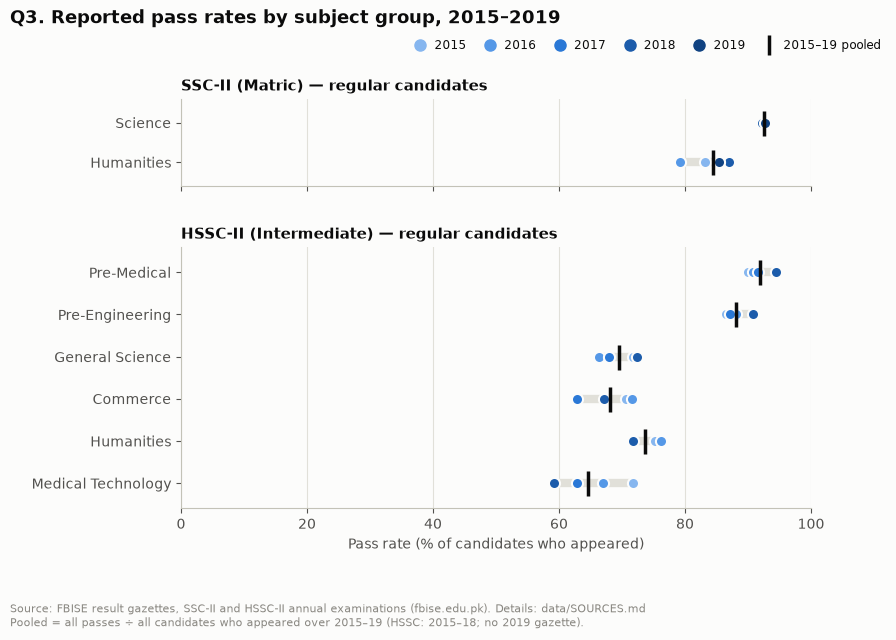

In [10]:
rates = analysis.group_pass_rates(df)
plots.plot_group_rates(rates);

In [11]:
(rates.drop_duplicates(["level", "group"])
      .set_index(["level", "group"])
      [["pooled_pass_rate", "lowest_year_rate", "highest_year_rate", "min_appeared",
        "comparable"]]
      .sort_values(["level", "pooled_pass_rate"], ascending=[True, False]))

pooled_pass_rate  lowest_year_rate  \
level group                                                    
HSSC  Pre-Medical                    91.83             89.93   
      Pre-Engineering                88.17             86.54   
      Humanities                     73.71             71.63   
      General Science                69.59             66.38   
      Commerce                       68.05             62.88   
      Medical Technology             64.59             59.16   
SSC   Science                        92.57             92.27   
      Humanities                     84.37             79.24   

                          highest_year_rate  min_appeared  comparable  
level group                                                            
HSSC  Pre-Medical                     94.45          9900        True  
      Pre-Engineering                 90.79         11948        True  
      Humanities                      76.20          7025        True  
      General Science                 72.31          9728        True  
      Commerce                        71.58          3797        True  
      Medical Technology              71.67           180        True  
SSC   Science                         92.91         49480        True  
      Humanities                      86.98          8149        True

**Interpretation.** Science-track groups had the highest reported pass
rates: SSC Science about 93% pooled, HSSC Pre-Medical about 92% and
Pre-Engineering about 88%. HSSC Humanities, General Science, Commerce and
Medical Technology were between about 65% and 74% pooled. In every year
Pre-Medical was first and Pre-Engineering second among HSSC groups, and SSC
Science was above SSC Humanities; the order of the other four HSSC groups changed
from year to year.

**Limitation.** Groups take different papers and attract different students,
so this is not a measure of how "hard" a group is. Medical Technology is small
(about 180–260 regular candidates a year), so its yearly rate moves more.

---
## Q4. How did 2020 (no exam) compare with the exam years?

**Method.** Pass rate by candidate type and level; 2020 compared with the
lowest and highest exam-year rate in 2015–2019.

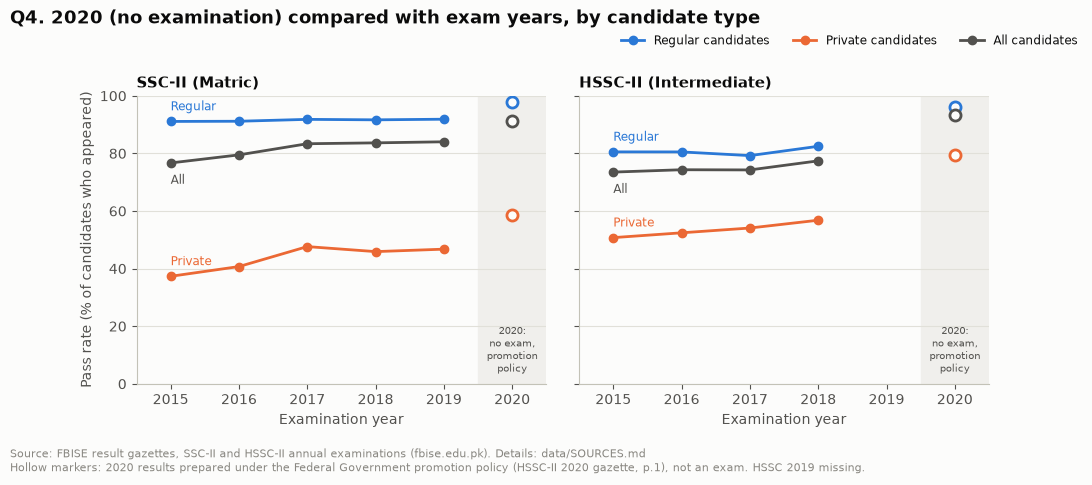

In [12]:
plots.plot_2020_comparison(analysis.candidate_type_trend(df));

In [13]:
compare = analysis.compare_2020(df)
compare["fail_share_2020_pct"] = compare["fail_2020"] / compare["appeared_2020"] * 100
compare["result_later_share_2020_pct"] = (compare["result_later_2020"]
                                          / compare["appeared_2020"] * 100)
compare.drop(columns=["fail_2020", "result_later_2020"])

,level,candidate_type,exam_years,lowest_exam_year_rate,highest_exam_year_rate,rate_2020,pp_above_highest_exam_year,appeared_2020,fail_share_2020_pct,result_later_share_2020_pct
0,HSSC,Regular,"2015, 2016, 2017, 2018",79.23,82.47,95.97,13.51,59512,0.34,4.03
1,SSC,Regular,"2015, 2016, 2017, 2018, 2019",91.10,91.87,97.67,5.80,78005,1.25,2.33
2,HSSC,Private,"2015, 2016, 2017, 2018",50.76,56.80,79.53,22.73,11970,0.31,20.47
3,SSC,Private,"2015, 2016, 2017, 2018, 2019",37.33,47.64,58.57,10.93,15299,0.55,41.43
4,HSSC,All,"2015, 2016, 2017, 2018",73.51,77.41,93.22,15.81,71482,0.34,6.78
5,SSC,All,"2015, 2016, 2017, 2018, 2019",76.69,84.03,91.26,7.23,93304,1.13,8.74


In [14]:
# How many candidates were declared 'fail' in the exam years, for context.
totals = analysis.select(df, candidate_type="All", group="All", gender="All")
totals = totals[totals["pass_rate_method"] == "computed_from_counts"]
totals.assign(fail_share_pct=totals["fail"] / totals["appeared"] * 100,
              result_later_share_pct=totals["result_later"] / totals["appeared"] * 100)[
    ["level", "year", "assessment", "appeared", "fail", "fail_share_pct",
     "result_later_share_pct"]]

,level,year,assessment,appeared,fail,fail_share_pct,result_later_share_pct
40,HSSC,2015,examination,56396,14910,26.44,0.09
79,HSSC,2016,examination,58032,14841,25.57,0.08
118,HSSC,2017,examination,57179,14675,25.67,0.41
157,HSSC,2018,examination,59568,13400,22.5,0.08
195,HSSC,2020,no_exam_promotion_policy,71482,240,0.34,6.78
212,SSC,2015,examination,78915,18347,23.25,0.17
227,SSC,2016,examination,82894,16969,20.47,0.25
242,SSC,2017,examination,85140,14116,16.58,0.35
259,SSC,2018,examination,89443,14551,16.27,0.25
274,SSC,2019,examination,87114,13863,15.91,0.47


**Interpretation.** Every 2020 figure was above every exam-year figure for
the same level and candidate type. The difference was largest for private
candidates (about 11 pp above their best exam year for SSC, about 23 pp for
HSSC). Almost nobody was recorded as failing in 2020 (about 1% of SSC and 0.3%
of HSSC candidates), compared with about 16–26% in the exam years. Most of those
who did not pass in 2020 were listed as "result later" (about 7–9% of candidates,
against under 0.5% in exam years). For private candidates the "result later"
share was large (about 41% for SSC and 20% for HSSC), so their 2020 pass rates are
not final figures: they count still-undecided candidates as not passed.

**Limitation.** 2020 results were produced by a policy, not by an exam, so
they are a different kind of number. The comparison only shows how different
the reported figures were. It says nothing about what students learned in
2020.

---
## Overall limitations

* **One board.** FBISE's candidates (federal-area and FBISE-affiliated
  institutions across Pakistan and overseas, plus private candidates) are not
  representative of Pakistan's provincial boards.
* **Short, incomplete series.** Full breakdowns exist for 2015–2019 only (HSSC
  2019 missing); 2013–14 have an overall rate only.
* **Definitions may change.** Grading, syllabus and paper patterns can change
  between years without appearing in the gazettes.
* **Descriptive only.** No result here establishes a cause.

Sources, extraction steps and every cleaning rule: `data/SOURCES.md`,
`DECISIONS.md`, `docs/CODE_WALKTHROUGH.md`.